# 00 — Xem data trước khi phân tích

Chạy từng phần thì mở notebook này trước: xem data đã xử lý trông như thế nào, trước khi chạy các bước phân tích. Data đã có sẵn trong git (3 file theo giờ + 3 file theo ngày, cả năm 2015), nên notebook này chạy được ngay mà không cần chạy lại pipeline.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thư mục gốc của repo (notebook nằm trong notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Repo root:", ROOT)
print("Python:", sys.executable)

Repo root: /home/hatch/workspace/data-mining-project/repo
Python: /home/hatch/workspace/data-mining-project/.venv/bin/python


## 1. Data theo giờ (`data/hourly_full_year/`)

Mỗi hệ 1 file, 8.760 giờ (System 1403: 8.730 giờ, thiếu 30 giờ do 2 khoảng trống qua đêm).

In [2]:
for sid, site in {4: 'Golden, CO (1 kW)', 1278: 'Las Vegas, NV (171,36 kW)', 1403: 'Cocoa Beach, FL (6 kW)'}.items():
    df = pd.read_csv(ROOT / f"data/hourly_full_year/system_{sid}_2015_hourly.csv",
                     parse_dates=["timestamp"])
    print(f"--- System {sid} ({site}): {len(df)} giờ, {len(df.columns)} cột")
    print("Cột:", list(df.columns))
    print(df[["ac_power_w", "poa_irradiance_wm2", "ambient_temp_c",
              "module_temp_c"]].describe().round(1))
    print("Số giờ thiếu AC:", df["ac_power_w"].isna().sum(),
          "| thiếu nhiệt độ môi trường:", df["ambient_temp_c"].isna().sum())


--- System 4 (Golden, CO (1 kW)): 8760 giờ, 7 cột
Cột: ['timestamp', 'ac_power_w', 'dc_power_w', 'poa_irradiance_wm2', 'ambient_temp_c', 'module_temp_c', 'n_samples']
       ac_power_w  poa_irradiance_wm2  ambient_temp_c  module_temp_c
count      8760.0              8760.0          8760.0         8760.0
mean        164.0               216.8            11.6           15.8
std         257.8               329.2            10.2           15.3
min           0.0                 0.0           -15.9          -17.1
25%           2.8                 0.0             4.7            4.6
50%           3.0                 6.1            12.2           14.0
75%         255.9               351.7            19.3           25.1
max         941.7              1293.9            34.7           59.1
Số giờ thiếu AC: 0 | thiếu nhiệt độ môi trường: 0
--- System 1278 (Las Vegas, NV (171,36 kW)): 8760 giờ, 10 cột
Cột: ['timestamp', 'ac_power_w', 'dc_power_w', 'poa_irradiance_wm2', 'ambient_temp_c', 'module_temp_

## 2. Tương quan công suất – bức xạ (chỉ giờ ban ngày, bức xạ > 50 W/m²)

In [3]:
for sid in [4, 1278, 1403]:
    df = pd.read_csv(ROOT / f"data/hourly_full_year/system_{sid}_2015_hourly.csv")
    day = df[df["poa_irradiance_wm2"] > 50]
    print(f"System {sid}: {len(day)} giờ ban ngày, "
          f"tương quan AC–bức xạ = {day['ac_power_w'].corr(day['poa_irradiance_wm2']):.3f}, "
          f"năng lượng cả năm = {df['ac_power_w'].sum() / 1000:.1f} kWh")

System 4: 3736 giờ ban ngày, tương quan AC–bức xạ = 0.942, năng lượng cả năm = 1436.8 kWh
System 1278: 4001 giờ ban ngày, tương quan AC–bức xạ = 0.980, năng lượng cả năm = 260414.4 kWh


System 1403: 3818 giờ ban ngày, tương quan AC–bức xạ = 0.964, năng lượng cả năm = 9067.6 kWh


## 3. Năng lượng theo ngày trong năm (365 ngày/hệ)

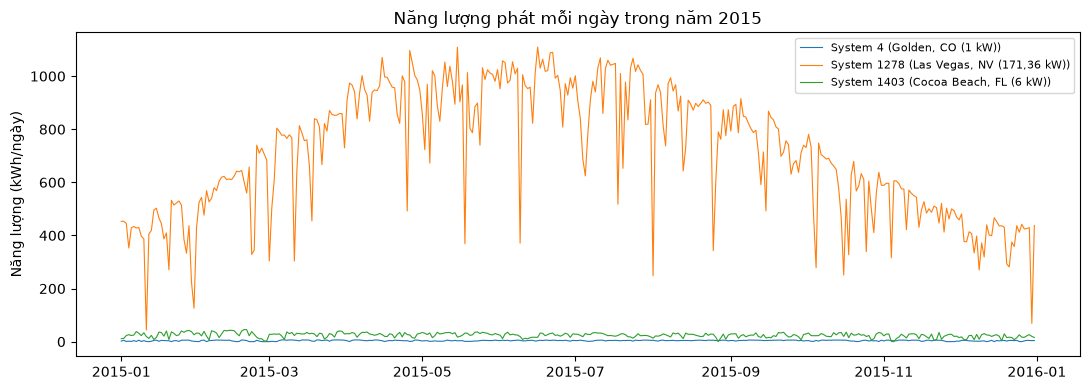

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
for sid, site in {4: 'Golden, CO (1 kW)', 1278: 'Las Vegas, NV (171,36 kW)', 1403: 'Cocoa Beach, FL (6 kW)'}.items():
    d = pd.read_csv(ROOT / f"data/daily_full_year/system_{sid}_2015_daily.csv",
                    parse_dates=["date"])
    ax.plot(d["date"], d["energy_kWh"], label=f"System {sid} ({site})", lw=0.8)
ax.set_ylabel("Năng lượng (kWh/ngày)")
ax.set_title("Năng lượng phát mỗi ngày trong năm 2015")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lưu ý:** timestamp là giờ địa phương từng bang (Golden, Las Vegas, Cocoa Beach khác nhau), đừng merge 3 hệ theo timestamp khi chưa đổi về chung một múi giờ. System 1403 có QA `fail` trong danh sách PVDAQ, dùng thận trọng — xem `docs/DATA_SOURCES.md`.